# 02 - Data Cleaning & Feature Engineering

Demonstrates ERA5 unit conversion, sentinel handling, temporal features, polar-night detection, and extreme-cold flags.

In [3]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(".").resolve().parent if Path(".").resolve().name == "notebooks" else Path(".").resolve()
sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\ankit\Desktop\PolarGrid_AI


## 1. Clean the Raw ERA5 Weather Data

In [4]:
from src.data.cleaning import clean_era5

era5_path = PROJECT_ROOT / "data" / "raw" / "ERA5" / "ERA5_raw_original.csv"
df_era5_raw = pd.read_csv(era5_path, nrows=2000)
df_weather = clean_era5(df_era5_raw)

print("Raw shape:", df_era5_raw.shape)
print("Cleaned shape:", df_weather.shape)
display(df_weather.head())

Raw shape: (2000, 12)
Cleaned shape: (2000, 13)


,valid_time,latitude,longitude,temperature_c,dewpoint_c,pressure_hpa,u10,v10,wind_speed_ms,solar_irradiance_wm2,thermal_down_wm2,precipitation_mm,cloud_cover
0,2012-01-01 00:00:00,-70.75,11.75,-3.77988,-9.62960,958.4575,-8.101105,4.208939,9.129242,44.462222,218.203056,0.000000,0.575195
1,2012-01-01 01:00:00,-70.75,11.75,-3.85950,-10.05656,958.0494,-8.152420,4.641830,9.381287,56.426667,218.254667,0.000000,0.577118
2,2012-01-01 02:00:00,-70.75,11.75,-3.79880,-10.26462,957.9189,-8.204605,4.844925,9.528318,83.040000,225.927292,0.000477,0.752594
3,2012-01-01 03:00:00,-70.75,11.75,-3.60364,-10.71030,957.1686,-8.163910,5.023605,9.585720,129.991111,225.914567,0.000477,0.782257
4,2012-01-01 04:00:00,-70.75,11.75,-3.48020,-11.17573,956.9908,-8.018738,5.141678,9.525598,197.280000,223.498139,0.000000,0.924377


## 2. Add Temporal and Antarctic Features

In [5]:
from src.data.feature_engineering import create_features

df_features = create_features(df_weather)
print("Engineered columns:", sorted(set(df_features.columns) - set(df_weather.columns)))
display(df_features[["timestamp", "hour", "season", "polar_night", "extreme_cold"]].head(10))

Engineered columns: ['day', 'day_of_week', 'day_of_year', 'extreme_cold', 'hour', 'humidity', 'month', 'polar_night', 'pressure', 'season', 'solar_radiation', 'temperature', 'timestamp', 'wind_direction', 'wind_speed', 'year']


,timestamp,hour,season,polar_night,extreme_cold
0,2012-01-01 00:00:00,0,0,0,0
1,2012-01-01 01:00:00,1,0,0,0
2,2012-01-01 02:00:00,2,0,0,0
3,2012-01-01 03:00:00,3,0,0,0
4,2012-01-01 04:00:00,4,0,0,0
5,2012-01-01 05:00:00,5,0,0,0
6,2012-01-01 06:00:00,6,0,0,0
7,2012-01-01 07:00:00,7,0,0,0
8,2012-01-01 08:00:00,8,0,0,0
9,2012-01-01 09:00:00,9,0,0,0


## 3. Inspect Polar Night and Extreme-Cold Indicators

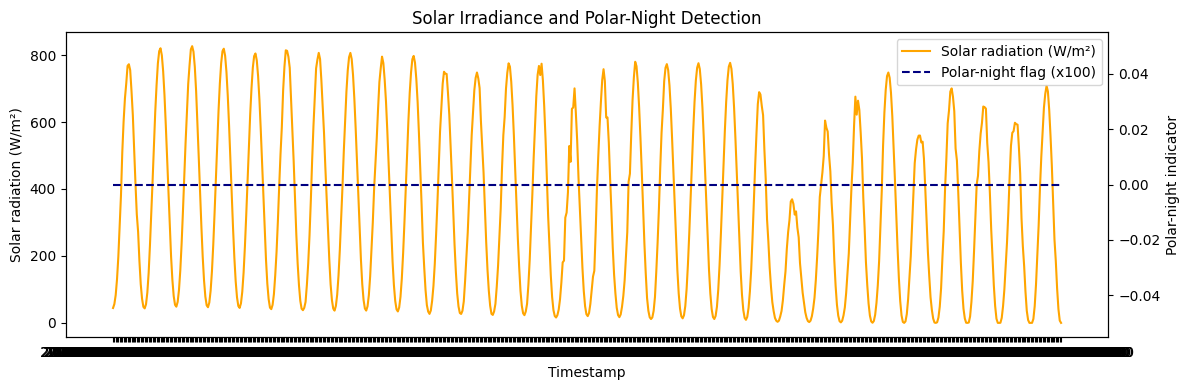

Extreme-cold rows: 0


In [6]:
plot_df = df_features.iloc[:720].copy()

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(plot_df["timestamp"], plot_df["solar_radiation"], color="orange", label="Solar radiation (W/m²)")
ax1.set_xlabel("Timestamp")
ax1.set_ylabel("Solar radiation (W/m²)")

ax2 = ax1.twinx()
ax2.plot(plot_df["timestamp"], plot_df["polar_night"] * 100, color="navy", linestyle="--", label="Polar-night flag (x100)")
ax2.set_ylabel("Polar-night indicator")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
ax1.set_title("Solar Irradiance and Polar-Night Detection")
fig.tight_layout()
plt.show()

print("Extreme-cold rows:", int(df_features["extreme_cold"].sum()))